# 패키징과 테스트 격리

**이 노트북에서 할 일**

1. 8절 모듈 price_tools를 패키지로 묶어 휠 파일을 만들고, 새 가상환경에 설치해 불러옵니다.
2. 두 테스트가 목록 하나를 함께 쓸 때 둘째 테스트가 실패하는 장면을 pytest로 봅니다.
3. 픽스처로 테스트마다 새 목록을 받게 해, 같은 두 테스트를 통과시킵니다.

**준비물** — API 키 불필요. 언어 모델 호출은 0번이고 비용은 들지 않습니다. 실행 시간은 1분 이내입니다.

패키지 도구 uv 0.12.11과 테스트 도구 pytest 9.1.1은 실습 폴더에서 `uv sync --locked`를 실행할 때 함께 설치됩니다.
이 절은 확장 경로(B)입니다. 1~10절과 같은 실습 폴더 `labs/part1/ch02-python`의 `.venv`를 커널로 고르고, 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

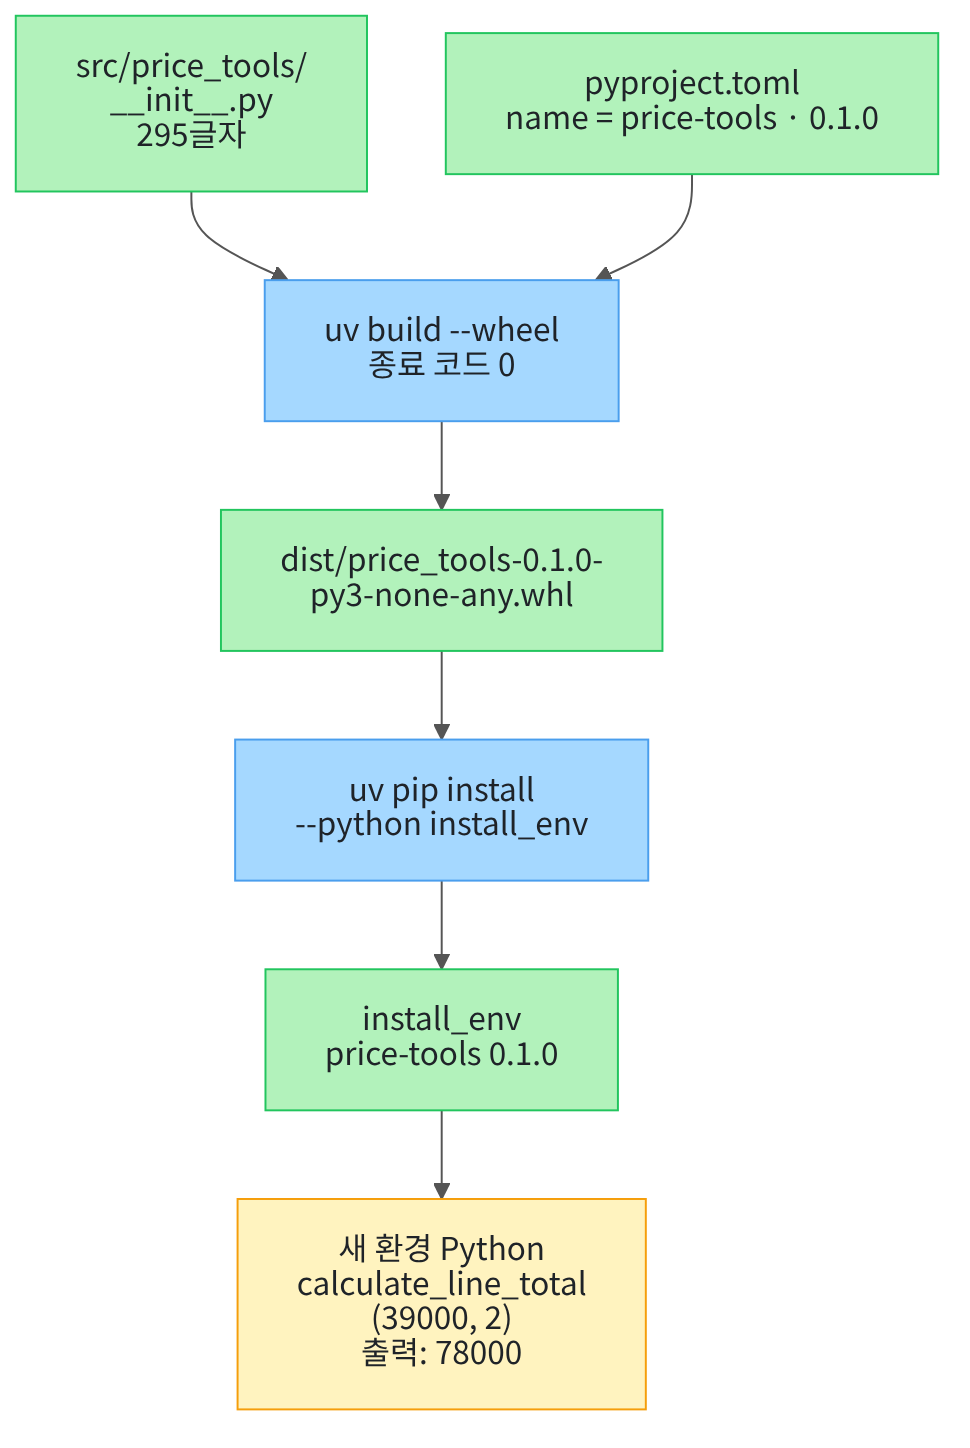

위에서 아래로 읽습니다. 초록 상자는 파일과 환경 폴더, 파란 상자는 우리가 실행한 명령, 노란 상자는 출력입니다.

코드 파일을 그대로 옮기지 않습니다. 휠 파일 하나로 묶은 뒤, 다른 가상환경에 설치해서 불러옵니다.

## 1. 준비

패키지 도구 uv는 실습 폴더의 pyproject.toml에 0.12.11 버전으로 적혀 있습니다.
8절에서 `python -m pytest`로 pytest를 실행한 것처럼, `python -m uv`로 uv를 실행합니다. 첫 준비 셀은 uv의 버전을 출력합니다.

오류 `No module named uv`가 나오면, Ch 1 3절처럼 커널이 실습 폴더의 `.venv`인지 확인합니다.

In [1]:
# 실습 폴더 가상환경에 설치된 패키지 도구 uv의 버전을 확인합니다
import subprocess
import sys

# 8절 run_pytest()처럼 지금 커널의 Python으로 모듈 uv를 실행합니다
version_command = [sys.executable, "-m", "uv", "--version"]
version_result = subprocess.run(version_command, capture_output=True, text=True)
# strip()으로 출력 끝의 줄바꿈을 지웁니다
version_text = version_result.stdout.strip()
print("uv 버전:", version_text)

uv 버전: uv 0.12.11 (aarch64-unknown-linux-gnu)


**결과 읽기** — uv 버전 줄은 `uv 0.12.11`로 시작하고, pyproject.toml에 적은 버전과 같습니다.
괄호 안은 컴퓨터 종류를 나타내서 사람마다 다를 수 있습니다.

이 노트북은 패키지 폴더와 휠 파일, 가상환경 폴더, 테스트 파일을 만듭니다. 5·7·8절처럼 빈 임시 폴더를 만들고, 그 폴더로 작업 위치를 옮깁니다.

In [2]:
# 파일을 둘 빈 임시 폴더를 만들고, 그 폴더로 작업 위치를 옮깁니다
import os
import tempfile

# mkdtemp()는 운영체제 임시 폴더 안에 새 폴더를 만들고 그 경로를 반환합니다
practice_folder = tempfile.mkdtemp(prefix="ch02-11-")
# chdir()는 터미널의 cd처럼 현재 작업 폴더를 옮깁니다
os.chdir(practice_folder)
file_names = os.listdir()
print("현재 작업 폴더의 파일:", file_names)

현재 작업 폴더의 파일: []


**결과 읽기** — 현재 작업 폴더의 파일은 `[]`로, 빈 폴더에서 시작합니다.
폴더의 경로는 컴퓨터마다 달라서 출력하지 않았습니다.

## 2. 모듈을 패키지 폴더에 담기

지금까지 모듈 파일은 노트북과 같은 폴더에 두고 불러왔습니다. 다른 폴더의 Python이나 다른 가상환경은 이 파일을 찾지 못합니다.
Ch 1 3절에서 패키지는 따로 설치하는 기능 묶음이라고 했습니다. pytest나 pydantic처럼, 우리 코드도 설치할 수 있게 묶어 봅니다.

패키지 도구 uv는 기본으로 `src/패키지 이름/__init__.py` 자리에서 코드를 찾습니다.
폴더 이름은 뒤에서 설정 파일에 적을 패키지 이름 price-tools의 하이픈을 밑줄로 바꾼 price_tools입니다.
이 폴더 이름이 import에 쓰는 이름이 됩니다. 파일 `__init__.py`는 `import price_tools`를 할 때 실행되는 파일입니다.

아래 셀은 8절 After의 price_tools.py 글을 그대로 이 파일에 저장합니다.
실행 전에 예상합니다. 쓴 글자 수는 8절 After와 같은 295일 것입니다.

In [3]:
# 8절 After의 price_tools.py 글을 폴더 src/price_tools 안의 __init__.py에 저장합니다
module_text = """def calculate_line_total(unit_price: int, quantity: int = 1) -> int:
    line_total = unit_price * quantity
    return line_total


def read_unit_price(price_line: str) -> int:
    product_name, unit_price_text = price_line.split(",")
    unit_price = int(unit_price_text)
    return unit_price
"""
# makedirs()는 폴더 price_tools를 만들 때 중간 폴더 src도 함께 만듭니다
os.makedirs("src/price_tools")
with open("src/price_tools/__init__.py", "w", encoding="utf-8") as file:
    written_count = file.write(module_text)
print("쓴 글자 수:", written_count)
print("src/price_tools 안의 파일:", os.listdir("src/price_tools"))

쓴 글자 수: 295
src/price_tools 안의 파일: ['__init__.py']


**결과 읽기** — 쓴 글자 수는 `295`이고, src/price_tools 안의 파일은 `['__init__.py']`로 예상과 같습니다.
함수 두 개는 8절 After와 같습니다. 파일의 자리만 패키지 폴더로 바뀌었습니다.

## 3. 설정 파일 pyproject.toml 쓰기

설치 도구는 코드 파일만 보고 패키지 이름과 버전을 알 수 없습니다. 그래서 설정 파일 pyproject.toml에 적어 둡니다.
대괄호로 둘러싼 줄 `[project]`는 구역 이름입니다. 그 아래에 `name = "price-tools"`처럼 키와 값을 한 줄씩 적습니다.

구역 `[project]`에는 패키지 이름과 버전을 적습니다. 설치할 때 부르는 이름은 하이픈을 쓴 price-tools입니다.
uv 문서는 이름의 하이픈을 밑줄로 바꿔 모듈 이름을 정한다고 설명합니다. 그래서 import 이름은 price_tools입니다.

구역 `[build-system]`에는 설치용 파일을 만들 도구를 적습니다. 이런 도구를 빌드 백엔드(build backend)라고 합니다.
키 `requires`는 그 도구의 패키지와 버전이고, 키 `build-backend`는 그 도구의 이름 uv_build입니다.

실행 전에 예상합니다. 현재 작업 폴더에는 pyproject.toml과 src 두 개가 보일 것입니다.

In [4]:
# 패키지 이름·버전과 빌드 도구를 적은 설정 파일 pyproject.toml을 저장합니다
project_text = """[project]
name = "price-tools"
version = "0.1.0"

[build-system]
requires = ["uv_build==0.12.11"]
build-backend = "uv_build"
"""
with open("pyproject.toml", "w", encoding="utf-8") as file:
    written_count = file.write(project_text)
# listdir()는 순서를 정하지 않고 반환하므로 sorted()로 이름 순서로 정렬합니다
file_names = sorted(os.listdir())
print("쓴 글자 수:", written_count)
print("현재 작업 폴더의 파일:", file_names)

쓴 글자 수: 125
현재 작업 폴더의 파일: ['pyproject.toml', 'src']


**결과 읽기** — 쓴 글자 수는 `125`이고, 현재 작업 폴더의 파일은 `['pyproject.toml', 'src']`로 예상과 같습니다.
실습 폴더에도 같은 이름의 설정 파일이 있습니다. 그 파일에는 이 실습에 쓰는 패키지와 버전이 적혀 있습니다.

## 4. 휠 파일 만들기 — uv build

빌드(build)는 코드와 설정을 읽어 설치용 파일을 만드는 일입니다. 만든 파일을 휠(wheel)이라고 부르고, 확장자는 `.whl`입니다.
명령 `uv build --wheel`은 현재 작업 폴더의 pyproject.toml을 읽고, 폴더 dist에 휠 파일을 만듭니다.

도구 uv는 진행 안내를 stdout이 아니라 stderr에 씁니다. Ch 1 3절에서 본 것처럼, stderr는 오류와 안내 글이 나오는 곳입니다.
그래서 이 셀은 `build_result.stderr`를 출력합니다. 옵션 `--color never`는 8절 `--color=no`처럼 출력 글에 색 기호를 넣지 않습니다.

실행 전에 예상합니다. 종료 코드는 0이고, 폴더 dist에 이름이 price_tools로 시작하는 파일이 생길 것입니다.

In [5]:
# 현재 작업 폴더의 pyproject.toml을 읽어 휠 파일을 만듭니다
build_command = [sys.executable, "-m", "uv", "build", "--wheel", "--color", "never"]
build_result = subprocess.run(build_command, capture_output=True, text=True)
# uv는 진행 안내를 stderr에 씁니다
print(build_result.stderr)
print("종료 코드:", build_result.returncode)
dist_names = sorted(os.listdir("dist"))
print("dist 안의 파일:", dist_names)

Successfully built dist/price_tools-0.1.0-py3-none-any.whl

종료 코드: 0
dist 안의 파일: ['.gitignore', 'price_tools-0.1.0-py3-none-any.whl']


**결과 읽기** — 안내 둘째 줄은 `Successfully built dist/price_tools-0.1.0-py3-none-any.whl`이고, 종료 코드는 `0`입니다.
dist 안의 파일은 `['.gitignore', 'price_tools-0.1.0-py3-none-any.whl']`입니다.

휠 파일 이름은 패키지 이름, 버전 0.1.0, 표시 py3-none-any를 붙여 만듭니다. 표시 py3-none-any는 Python 3이면 운영체제와 상관없이 설치할 수 있다는 뜻입니다.
파일 .gitignore는 uv가 함께 만든 Git 설정 파일입니다. Git 설정은 Ch 3에서 배웁니다.

## 5. 휠 안의 파일 보기

휠 파일은 여러 파일을 하나로 묶은 zip 압축 파일입니다. 표준 라이브러리 모듈 zipfile로 열면 안에 든 파일 이름을 볼 수 있습니다.
클래스 `zipfile.ZipFile`을 부르면 5절 `open()`처럼 with 블록에서 압축 파일을 엽니다. 메서드 `namelist()`는 안에 든 파일 이름 목록을 반환합니다.

실행 전에 예상합니다. 우리가 쓴 `__init__.py`가 들어 있을 것입니다. 폴더 src도 휠에 들어갈까요?

In [6]:
# 휠 파일을 zip 압축 파일로 열어, 안에 든 파일 이름을 한 줄씩 출력합니다
import zipfile

wheel_path = "dist/price_tools-0.1.0-py3-none-any.whl"
# ZipFile()은 압축 파일을 열고, namelist()는 안에 든 파일 이름 목록을 반환합니다
with zipfile.ZipFile(wheel_path) as wheel_file:
    inside_names = wheel_file.namelist()
for inside_name in inside_names:
    print("휠 안:", inside_name)

휠 안: price_tools/
휠 안: price_tools/__init__.py
휠 안: price_tools-0.1.0.dist-info/
휠 안: price_tools-0.1.0.dist-info/WHEEL
휠 안: price_tools-0.1.0.dist-info/METADATA
휠 안: price_tools-0.1.0.dist-info/RECORD


**결과 읽기** — 출력은 여섯 줄입니다. 첫 두 줄은 `price_tools/`와 `price_tools/__init__.py`입니다. 나머지 네 줄은 `price_tools-0.1.0.dist-info/`로 시작합니다.

슬래시로 끝나는 이름은 폴더입니다. 폴더 src는 휠에 없고, import 이름 폴더 price_tools가 맨 위에 있습니다.
폴더 dist-info에는 `METADATA`, `WHEEL`, `RECORD` 세 파일이 있습니다. 패키징 문서는 METADATA에 이름과 버전이 적힌다고 설명합니다. 이번에는 세 파일의 내용을 열어 보지 않았습니다.

## 6. 설치할 새 가상환경 만들기

휠이 제대로 만들어졌는지는 설치하고 불러와 봐야 압니다.
실습 폴더의 .venv는 `uv sync --locked`가 잠금 파일대로 맞추는 환경이라 건드리지 않습니다. Ch 1 3절처럼 빈 가상환경을 새로 만듭니다.

명령 `uv venv install_env --python`은 폴더 install_env에 가상환경을 만듭니다. 옵션 `--python` 뒤에는 지금 커널의 Python을 적어 같은 버전을 씁니다.
Ch 1 3절처럼 운영체제에 따라 환경 안의 Python 위치가 다릅니다. 함수 `os.path.join()`은 폴더 이름들을 운영체제에 맞는 구분 기호로 이어 줍니다.

실행 전에 예상합니다. 종료 코드는 0이고, 설정 파일 pyvenv.cfg가 생길 것입니다.

In [7]:
# Ch 1 3절처럼 폴더 install_env에 빈 가상환경을 만듭니다(지금 커널과 같은 Python 사용)
venv_command = [sys.executable, "-m", "uv", "venv", "install_env", "--python", sys.executable]
venv_result = subprocess.run(venv_command, capture_output=True, text=True)
print("종료 코드:", venv_result.returncode)
# 운영체제에 맞게 새 환경 안의 Python 실행 파일 위치를 정합니다
if sys.platform == "win32":
    env_python = os.path.join("install_env", "Scripts", "python.exe")
else:
    env_python = os.path.join("install_env", "bin", "python")
env_files = os.listdir("install_env")
print("새 환경의 Python:", env_python)
print("pyvenv.cfg 파일이 있는가:", "pyvenv.cfg" in env_files)

종료 코드: 0
새 환경의 Python: install_env/bin/python
pyvenv.cfg 파일이 있는가: True


**결과 읽기** — 종료 코드는 `0`, 새 환경의 Python은 `install_env/bin/python`, pyvenv.cfg 파일이 있는가는 `True`입니다.
교재 출력은 Linux 방식의 경로입니다. Windows에서는 실행하지 않았고, `Scripts` 폴더 경로가 나올 것으로 봅니다.

## 7. 휠 설치하기 — uv pip install

명령 `uv pip install`은 휠 파일을 받아 가상환경에 설치합니다. 옵션 `--python` 뒤에 새 환경의 Python을 적어, 그 환경에 설치하게 합니다.
설치가 끝나면 명령 `uv pip list`로 같은 환경에 설치된 패키지 목록을 출력합니다.

실행 전에 예상합니다. 목록에는 이름 price-tools와 버전 0.1.0이 보일 것입니다.

In [8]:
# 새 환경의 Python을 골라 휠 파일을 설치합니다
install_command = [sys.executable, "-m", "uv", "pip", "install", "--python", env_python, wheel_path]
install_result = subprocess.run(install_command, capture_output=True, text=True)
print("종료 코드:", install_result.returncode)
# 같은 환경에 설치된 패키지 목록을 출력합니다
list_command = [sys.executable, "-m", "uv", "pip", "list", "--python", env_python]
list_result = subprocess.run(list_command, capture_output=True, text=True)
print(list_result.stdout)

종료 코드: 0
Package     Version
----------- -------
price-tools 0.1.0



**결과 읽기** — 종료 코드는 `0`입니다. 패키지 목록의 마지막 줄은 `price-tools 0.1.0`입니다.
목록에는 pyproject.toml에 적은 이름 price-tools가 나옵니다. import 이름 price_tools와 다릅니다. 빈 환경에 설치해서 다른 패키지는 없습니다.

## 8. 새 환경의 Python에서 불러오기

Ch 1 3절처럼, 실행할 코드를 글로 적어 옵션 `-c` 뒤에 넣습니다. 글 안의 `\n`은 줄바꿈입니다.
첫 줄은 7절 from import 문이고, 둘째 줄은 7·8절의 단가 39000, 수량 2로 금액을 출력합니다.

현재 작업 폴더에서 폴더 price_tools는 src 안에 있어 바로 보이지 않습니다.
그래서 불러오기에 성공하면, 새 환경에 설치된 패키지를 불러온 것입니다.

실행할 Python은 이름 python_path에 담아 둡니다. 실행 전에 예상합니다. 출력은 78000, 종료 코드는 0일 것입니다.

In [9]:
# 설치한 패키지에서 함수를 불러와 금액을 출력하는 코드 글을, 새 환경의 Python으로 실행합니다
check_code = "from price_tools import calculate_line_total\nprint(calculate_line_total(39000, 2))"
python_path = env_python
check_result = subprocess.run([python_path, "-c", check_code], capture_output=True, text=True)
# strip()으로 출력 끝의 줄바꿈을 지웁니다
check_output = check_result.stdout.strip()
print("출력:", check_output)
print("종료 코드:", check_result.returncode)

출력: 78000
종료 코드: 0


**결과 읽기** — 출력은 `78000`, 종료 코드는 `0`으로 예상과 같습니다.
7·8절과 같은 금액입니다. 이번에는 노트북 옆의 모듈 파일이 아니라, 휠로 설치한 패키지에서 함수를 불러왔습니다.

## 9. 값 바꿔 보기 — 커널의 Python으로 실행하기

8번 셀에서 이름 python_path의 값 하나만 env_python에서 `sys.executable`로 바꿉니다. 코드 글 check_code는 그대로 둡니다.
값 `sys.executable`은 지금 커널의 Python입니다. 휠은 install_env에만 설치했습니다.

실행 전에 예상합니다. 출력은 비고 종료 코드는 0이 아닐 것입니다. 오류 설명은 stderr에 있으므로, 그 마지막 줄을 출력합니다.

In [10]:
# 값 바꿔 보기: 실행할 Python만 지금 커널의 Python으로 바꿉니다
python_path = sys.executable
check_result = subprocess.run([python_path, "-c", check_code], capture_output=True, text=True)
check_output = check_result.stdout.strip()
print("출력:", check_output)
print("종료 코드:", check_result.returncode)
# 오류 설명의 마지막 줄에 오류 이름과 메시지가 있습니다
error_lines = check_result.stderr.splitlines()
print("stderr 마지막 줄:", error_lines[-1])

출력: 
종료 코드: 1
stderr 마지막 줄: ModuleNotFoundError: No module named 'price_tools'


**결과 읽기** — 출력은 비었고, 종료 코드는 `1`입니다. stderr 마지막 줄은 `ModuleNotFoundError: No module named 'price_tools'`입니다.

Ch 1 3절에서 커널에 없는 패키지를 불렀을 때와 같은 오류 이름입니다. 같은 코드 글도 설치한 환경의 Python에서만 실행됩니다.
폴더 src가 있다고 불러와지는 것이 아닙니다. 8번 셀의 78000은 설치한 휠에서 나온 결과입니다.

## 10. Before — 두 테스트가 목록 하나를 함께 씀

이제 테스트로 넘어갑니다. 8절과 같은 함수 `run_pytest()`로, 현재 작업 폴더의 테스트를 새 Python에서 실행합니다.
테스트 도구 pytest는 설정 파일 pyvenv.cfg가 있는 폴더를 가상환경으로 봅니다. 그 폴더 안에서는 테스트 파일을 찾지 않습니다.

실행 전에 예상합니다. 정의 셀이라 출력은 없을 것입니다.

In [11]:
# 8절과 같은 함수: 현재 작업 폴더의 테스트를 새 Python에서 pytest로 실행하고, 종료 코드를 반환합니다
def run_pytest() -> int:
    # 터미널에서 python -m pytest -q --color=no를 입력하는 것과 같은 명령 목록입니다
    command = [sys.executable, "-m", "pytest", "-q", "--color=no"]
    result = subprocess.run(command, capture_output=True, text=True)
    print(result.stdout)
    return result.returncode

**결과 읽기** — 예상대로 출력이 없습니다. 함수 본문은 8절 `run_pytest()`와 같습니다.

주문 줄의 상품을 목록에 담는 동작을 테스트한다고 합니다. 테스트 파일 맨 위에 빈 목록 items를 한 번만 만들어 둡니다.
테스트 함수 test_add_note는 목록에 노트를, test_add_pencil은 연필을 담습니다. 두 테스트 모두 자기가 담은 상품 하나만 목록에 있기를 기대합니다.

6절 Before에서 클래스 본문에 `items = []`를 두자, 두 주문이 목록 하나를 함께 썼습니다. 이 테스트 파일의 목록도 파일에 하나뿐입니다.
이 셀은 글을 저장만 하고, 테스트는 아직 실행하지 않습니다.

In [12]:
# 파일 맨 위의 목록 items 하나를 두 테스트 함수가 함께 쓰는 테스트 파일을 저장합니다
test_text = """items = []


def test_add_note():
    items.append("노트")
    assert items == ["노트"]


def test_add_pencil():
    items.append("연필")
    assert items == ["연필"]
"""
with open("test_items.py", "w", encoding="utf-8") as file:
    written_count = file.write(test_text)
print("쓴 글자 수:", written_count)

쓴 글자 수: 159


**결과 읽기** — 쓴 글자 수는 `159`입니다. 테스트 파일 하나에 테스트 함수가 두 개 있습니다.

파일 이름을 적지 않았으므로, pytest는 현재 작업 폴더에서 test_items.py를 찾아 두 테스트를 차례로 실행합니다.

실행 전에 예상해 봅니다. 각 테스트는 상품을 하나만 담습니다. 두 테스트 모두 통과할까요?

In [13]:
# 목록 하나를 함께 쓰는 두 테스트를 pytest로 실행합니다
exit_code = run_pytest()
print("종료 코드:", exit_code)

.F                                                                       [100%]
=================================== FAILURES ===================================
_______________________________ test_add_pencil ________________________________

    def test_add_pencil():
        items.append("연필")
>       assert items == ["연필"]
E       AssertionError: assert ['노트', '연필'] == ['연필']
E         
E         At index 0 diff: '노트' != '연필'
E         Left contains one more item: '연필'
E         Use -v to get more diff

test_items.py:11: AssertionError
=========================== short test summary info ============================
FAILED test_items.py::test_add_pencil - AssertionError: assert ['노트', '연필...
1 failed, 1 passed in 0.01s

종료 코드: 1


**결과 읽기** — 진행 줄은 `.F`이고, 요약 줄은 `1 failed, 1 passed`, 종료 코드는 `1`입니다. 점 하나는 먼저 실행한 test_add_note의 통과입니다.

실패한 테스트는 test_add_pencil입니다. E 줄 `AssertionError: assert ['노트', '연필'] == ['연필']`의 왼쪽이 실제 목록입니다.
앞 테스트가 담은 노트가 목록에 남아 있었고, 그 뒤에 연필이 더해졌습니다.

줄 `test_items.py:11`은 테스트 파일의 11번째 줄에서 멈췄다는 뜻입니다. 함수 test_add_pencil 안의 줄은 틀리지 않았습니다. 앞 테스트가 남긴 값이 결과를 바꿨습니다.

실패한 test_add_pencil만 따로 실행해 봅니다. 파일 이름 뒤에 `::`와 함수 이름을 붙이면, pytest는 그 테스트 함수 하나만 실행합니다.
이 셀은 명령 목록 끝에 `test_items.py::test_add_pencil`을 더해 subprocess로 바로 실행합니다.

실행 전에 예상합니다. 이번에는 앞에서 노트를 담는 테스트가 실행되지 않으므로 통과할 것입니다.

In [14]:
# 실패한 테스트 함수 test_add_pencil 하나만 새 Python에서 실행합니다
single_command = [sys.executable, "-m", "pytest", "-q", "--color=no", "test_items.py::test_add_pencil"]
single_result = subprocess.run(single_command, capture_output=True, text=True)
print(single_result.stdout)
print("종료 코드:", single_result.returncode)

.                                                                        [100%]
1 passed in 0.00s

종료 코드: 0


**결과 읽기** — 진행 줄은 점 `.` 하나, 요약 줄은 `1 passed`, 종료 코드는 `0`입니다.

같은 테스트 함수가 혼자 실행하면 통과하고, 다른 테스트 뒤에 실행하면 실패했습니다. 테스트 결과가 앞에서 실행된 테스트에 달려 있습니다.
테스트를 고르거나 순서를 바꿔 통과시키면, 목록을 함께 쓰는 문제는 그대로 남습니다.

## 11. After — 픽스처로 테스트마다 새 목록 받기

테스트 격리(test isolation)는 테스트마다 따로 준비한 값으로 실행하는 일입니다. 다른 테스트가 남긴 값이 끼어들지 않게 합니다.
마트 입구에서 손님마다 빈 바구니를 새로 꺼내 주는 것과 비슷합니다. 아래 테스트 파일에서는 픽스처가 테스트마다 빈 목록을 새로 만듭니다.

픽스처(fixture)는 테스트 함수에 넣어 줄 값을 준비하는 함수입니다. 함수 위의 `@pytest.fixture` 줄은 아래 함수 items를 픽스처로 등록합니다. 9절에서 배운 `@` 줄과 같은 규칙으로 읽습니다.
테스트 함수의 괄호에 픽스처 이름 items를 매개변수로 적습니다. 그러면 pytest가 테스트를 부르기 전에 픽스처 함수를 실행하고, 반환한 빈 목록을 넣어 줍니다.

Before 파일과 달라진 곳은 두 가지입니다. 맨 위의 목록 줄을 픽스처 함수로 바꾸고, 두 테스트 함수의 괄호에 items를 적었습니다. 상품을 담는 줄과 기대값은 그대로입니다.
실행 전에 예상합니다. 줄이 늘었으므로 쓴 글자 수는 Before의 159보다 클 것입니다.

In [15]:
# 목록 줄을 픽스처 함수로 바꾸고, 두 테스트 함수가 매개변수 items로 받게 테스트 파일을 다시 씁니다
test_text = """import pytest


@pytest.fixture
def items():
    return []


def test_add_note(items):
    items.append("노트")
    assert items == ["노트"]


def test_add_pencil(items):
    items.append("연필")
    assert items == ["연필"]
"""
with open("test_items.py", "w", encoding="utf-8") as file:
    written_count = file.write(test_text)
print("쓴 글자 수:", written_count)

쓴 글자 수: 217


**결과 읽기** — 쓴 글자 수는 `217`로, Before의 159보다 큽니다. 같은 파일 이름 test_items.py에 다시 썼습니다.

Before 셀과 같은 함수 `run_pytest()`로 같은 파일을 다시 실행합니다. 셀 끝에 종료 코드를 확인하는 `assert` 줄을 더합니다.

실행 전에 예상합니다. 두 테스트가 모두 통과해 점 두 개와 2 passed, 종료 코드 0이 나올 것입니다.

In [16]:
# 픽스처로 바꾼 두 테스트를 같은 함수로 다시 실행합니다
exit_code = run_pytest()
print("종료 코드:", exit_code)
# 테스트가 하나라도 실패해 종료 코드가 0이 아니면 이 줄에서 멈춥니다
assert exit_code == 0

..                                                                       [100%]
2 passed in 0.00s

종료 코드: 0


**결과 읽기** — 진행 줄은 `..`, 요약 줄은 `2 passed`, 종료 코드는 `0`입니다. 검사 줄 `assert`에서도 멈추지 않았습니다.

Before 셀의 .F와 비교하면 F 자리가 점으로 바뀌었습니다. 이번에는 test_add_pencil을 따로 실행하지 않고, 두 테스트를 함께 실행해서 통과했습니다.

픽스처 함수가 정말 테스트마다 다시 실행되는지 봅니다. 옵션 `--setup-show`를 더하면, pytest는 테스트 앞뒤에 픽스처를 준비하고 치운 줄을 함께 출력합니다.
출력의 SETUP은 준비, TEARDOWN은 치움입니다.

실행 전에 예상합니다. SETUP 줄이 테스트마다 한 번씩, 모두 두 번 나올 것입니다.

In [17]:
# 옵션 --setup-show를 더해, 테스트마다 픽스처를 준비하고 치우는 줄을 함께 출력합니다
show_command = [sys.executable, "-m", "pytest", "-q", "--color=no", "--setup-show"]
show_result = subprocess.run(show_command, capture_output=True, text=True)
print(show_result.stdout)
print("종료 코드:", show_result.returncode)


        SETUP    F items
        test_items.py::test_add_note (fixtures used: items) .
        TEARDOWN F items
        SETUP    F items
        test_items.py::test_add_pencil (fixtures used: items) .
        TEARDOWN F items
2 passed in 0.00s

종료 코드: 0


**결과 읽기** — `SETUP    F items` 줄이 두 번 나오고, 요약 줄은 `2 passed`입니다. 출력은 준비, 테스트, 치움 세 줄이 테스트마다 한 번씩 되풀이됩니다.

테스트 줄의 `(fixtures used: items)`는 그 테스트가 픽스처 items를 받았다는 뜻입니다.
글자 F는 픽스처가 테스트 함수 하나(function) 동안만 쓰인다는 표시입니다. pytest 소스에서 픽스처의 기본 범위는 function입니다.

두 번째 SETUP에서 픽스처 함수가 다시 실행되어, test_add_pencil은 노트가 없는 새 빈 목록을 받았습니다.

### 원리 더 알아보기 — 테스트 동안만 이름 바꾸기(monkeypatch)

주문 처리 상태를 알려 주는 함수가 실제로는 다른 컴퓨터에 물어본다고 해 봅니다. 테스트할 때마다 물어보지 않도록, 테스트 동안만 다른 함수로 바꿔 끼울 수 있습니다.
테스트 도구 pytest가 미리 만들어 둔 픽스처 monkeypatch가 이 일을 합니다. 지금은 출력만 읽습니다.

아래 셀의 함수 fetch_status는 다른 컴퓨터에 묻지 않고, 글자 '대기'를 반환하는 연습용 함수입니다.

In [18]:
# 원리 더 알아보기: 처리 상태를 알려 주는 연습용 모듈 파일 order_status.py를 저장합니다
status_text = """def fetch_status() -> str:
    return "대기"


def report_status() -> str:
    status = fetch_status()
    return "처리 상태: " + status
"""
with open("order_status.py", "w", encoding="utf-8") as file:
    written_count = file.write(status_text)
print("쓴 글자 수:", written_count)

쓴 글자 수: 131


**결과 읽기** — 쓴 글자 수는 `131`입니다. 함수 report_status는 함수 fetch_status가 반환한 글자를 붙여 반환합니다.

첫 테스트는 매개변수에 픽스처 이름 monkeypatch를 적습니다. 메서드 `setattr()`은 모듈 order_status의 이름 fetch_status가 테스트 동안 fake_status를 가리키게 합니다.
pytest 소스의 설명은 테스트 함수가 끝나면 바꾼 것을 모두 되돌린다고 적습니다. 둘째 테스트는 원래 함수의 '대기'가 나오는지 확인합니다.

이 셀은 테스트 파일을 하나 더 만들어, 앞의 test_items.py와 함께 실행합니다.

In [19]:
# 원리 더 알아보기: 첫 테스트에서만 함수를 바꿔 끼우고, 둘째 테스트에서 원래 함수를 확인합니다
patch_test_text = """import order_status


def fake_status():
    return "완료"


def test_fake_status(monkeypatch):
    monkeypatch.setattr(order_status, "fetch_status", fake_status)
    assert order_status.report_status() == "처리 상태: 완료"


def test_original_status():
    assert order_status.report_status() == "처리 상태: 대기"
"""
with open("test_order_status.py", "w", encoding="utf-8") as file:
    file.write(patch_test_text)
deep_exit_code = run_pytest()
print("종료 코드:", deep_exit_code)

....                                                                     [100%]
4 passed in 0.00s

종료 코드: 0


**결과 읽기** — 진행 줄은 점 `....` 네 개이고, 요약 줄은 `4 passed`입니다.
앞의 test_items.py 두 테스트에, test_order_status.py의 두 테스트가 더해졌습니다.
첫 테스트는 바꿔 끼운 함수로 「처리 상태: 완료」를 얻었습니다. 둘째 테스트는 되돌려진 원래 함수로 「처리 상태: 대기」를 얻었습니다.

## 정리

- 폴더 `src/price_tools/__init__.py`와 pyproject.toml을 `uv build --wheel`이 읽어 휠 파일을 만들었습니다. 휠 안에는 폴더 price_tools와 dist-info가 들었습니다.
- 새 가상환경에 휠을 설치하자 그 환경의 Python은 78000을 출력했고, 커널의 Python은 `ModuleNotFoundError`를 냈습니다.
- 목록 하나를 함께 쓴 두 테스트는 `.F`로 실패했고, 픽스처로 테스트마다 새 목록을 받게 하자 `2 passed`가 되었습니다.

기본 경로(A)와 확장 경로(B) 모두 12절 async와 await로 이어집니다.